In [57]:
# import packages 
from pathlib import Path
import pandas as pd 
import seaborn as sns

import requests
from bs4 import BeautifulSoup

#Seaborn Theme 
sns.set_theme(style='whitegrid', 
              context='notebook', 
              palette= "pastel", 
              font_scale=0.8, 
              rc={
                  "axes.titlesize": 20, 
                  "font.family": "serif"}
 )

In [2]:
# retrieve pesticide group website

url = "https://www.bcpcpesticidecompendium.org/class_pesticides.html"
response = requests.get(url)
response.raise_for_status()

webpage = BeautifulSoup(response.text, "html.parser")
type(webpage)
if webpage.title:
    print(webpage.title.get_text(strip = True))
else: print("No page title")

Pesticide classification


In [3]:
# herbicide
url = "https://www.bcpcpesticidecompendium.org/class_herbicides.html"
response = requests.get(url)
response.raise_for_status()

webpage = BeautifulSoup(response.text, "html.parser")
type(webpage)
if webpage.title:
    print(webpage.title.get_text(strip = True))
else: print("No page title")

herb = [entry.get_text(strip = True) for entry in webpage.select("li a") if entry.get_text(strip = True)]
herb

Classification of herbicides


['pelargonic acid',
 'diphenamid',
 'naproanilide',
 'napropamide',
 'napropamide-M',
 'chloranocryl',
 'cisanilide',
 'cypromid',
 'erlujixiancaoan',
 'etobenzanid',
 'monalide',
 'pentanochlor',
 'propanil',
 'dimepyrolimet',
 'tetflupyrolimet',
 'benzoylprop',
 'flamprop',
 'flamprop-M',
 'cafenstrole',
 'fentrazamide',
 'ipfencarbazone',
 'benzipram',
 'isoxaben',
 'propyzamide',
 'tebutam',
 'acetochlor',
 'alachlor',
 'allidochlor',
 'amidochlor',
 'butachlor',
 'butenachlor',
 'CDEA',
 'delachlor',
 'diethatyl',
 'dimethachlor',
 'dimethenamid',
 'dimethenamid-P',
 'ethachlor',
 'ethaprochlor',
 'metazachlor',
 'metolachlor',
 'S-metolachlor',
 'pethoxamid',
 'pretilachlor',
 'propachlor',
 'propisochlor',
 'prynachlor',
 'terbuchlor',
 'thenylchlor',
 'xylachlor',
 'quinonamid',
 'benzofluor',
 'pyrimisulfan',
 'triafamone',
 'dimesulfazet',
 'mefluidide',
 'perfluidone',
 'diflufenzopyr',
 'naptalam',
 'cambendichlor',
 'chloramben',
 'chlorthal',
 'dicamba',
 '2,3,6-TBA',
 't

In [4]:
# nevermind it should be a function...

def get_pesticides(pesticide_type):
    url = f"https://www.bcpcpesticidecompendium.org/class_{pesticide_type}.html"
    response = requests.get(url)
    response.raise_for_status()
    the_website = BeautifulSoup(response.text, "html.parser")

    pesticides = [entry.get_text(strip = True) for entry in the_website.select("li a") if entry.get_text(strip = True)]

    return pesticides

In [5]:
# use function for different pesticide categories

# pest_types = ["bactericides", "herbicides", "fungicides", "rodenticides", "nematicides"]
# im sure this could be made into a loop but i suck at them

bactericides = get_pesticides("bactericides")
herbicides = get_pesticides("herbicides")
fungicides = get_pesticides("fungicides")
rodenticides = get_pesticides("rodenticides")
nematicides = get_pesticides("nematicides")


In [7]:
# create dataframe to match to pesticide concentrations

categories = {
    "bactericides" : bactericides,
    "herbicides" : herbicides,
    "fungicides" : fungicides,
    "rodenticides" : rodenticides,
    "nematicides" : nematicides
}

pest_categories = pd.DataFrame(
    [(compound, category)
     for category, compounds in categories.items()
     for compound in compounds],
     columns = ["Compound", "Pesticide Category"]
)

pest_categories.head()

,Compound,Pesticide Category
0,pelargonic acid,herbicides
1,diphenamid,herbicides
2,naproanilide,herbicides
3,napropamide,herbicides
4,napropamide-M,herbicides


### Categorize

In [ ]:
# paths 
project_fldr = Path.cwd().parent
raw_fldr = project_fldr /'Data'/'unprocessed' 
processed_fldr = project_fldr /'Data'/'processed'

# import combined agri + water pest dataset
pest_water_use = pd.read_csv(processed_fldr/'pest_water_use_processed.csv')

In [28]:
#cleaning columns 
pest_water_use = pest_water_use.loc[:,['Pesticide_Name', 'Water_Year', 'Result_Value_ug_L', 'site_id', 'Drainage_area_km2','county_fips','EPEST_HIGH_KG','COMPOUND','geometry']]
pest_water_use["COMPOUND"].unique()

<StringArray>
[             '2,4-D',           'ACEPHATE',         'ACETOCHLOR',
           'ATRAZINE',       'AZOXYSTROBIN',           'BROMACIL',
         'BROMOXYNIL',           'CARBARYL',       'CHLORPYRIFOS',
           'DIAZINON',            'DICAMBA',        'DICROTOPHOS',
      'DIFLUBENZURON',       'DIMETHENAMID',         'DIMETHOATE',
             'DIURON',        'ETHOPROPHOS',          'ETOXAZOLE',
           'FIPRONIL',        'FLUOMETURON',         'GLYPHOSATE',
         'HEXAZINONE',        'IMAZETHAPYR',       'IMIDACLOPRID',
            'LINURON',          'MALATHION',          'METALAXYL',
        'METCONAZOLE',           'METHOMYL',    'METHOXYFENOZIDE',
        'METOLACHLOR',         'METRIBUZIN',       'MYCLOBUTANIL',
           'ORYZALIN', 'PIPERONYL BUTOXIDE',           'PROMETON',
          'PROPAZINE',      'PROPICONAZOLE',           'PROPOXUR',
     'PYRACLOSTROBIN',           'SIMAZINE',      'SULFENTRAZONE',
       'TEBUCONAZOLE',        'TEBUTHIURON',    

In [ ]:
print(pest_categories["Compound"].unique())
#slight problem the pest key has different compounds per category
# can brute force a key because pest_water_use only has 49 compounds but that is a later problem

search = pest_categories[pest_categories["Compound"] == "Tetraconazole"]
search.head()

<StringArray>
[ 'pelargonic acid',       'diphenamid',     'naproanilide',
      'napropamide',    'napropamide-M',     'chloranocryl',
       'cisanilide',         'cypromid',  'erlujixiancaoan',
      'etobenzanid',
 ...
      'fosthiazate',       'fosthietan',        'imicyafos',
       'diamidafos',         'xylenols',       'acetoprole',
 'fluazaindolizine',      'benclothiaz',      'fenargimine',
       'tioxazafen']
Length: 1138, dtype: str


,Compound,Pesticide Category


In [45]:
#left join between pest_water_use and pest_categories using compound column 
pest_water_categories = pd.merge(
    pest_water_use,
    pest_categories,
    left_on = "Pesticide_Name",
    right_on = "Compound",
    how = "left"
).drop(columns = "Compound")


missing = pest_water_categories.isna().mean().sort_values(ascending = False) * 100
missing.head()

#yeouch definitely need to fix i will manually create a csv an attempt at web scraping was at least made :(


Pesticide Category    96.552914
Drainage_area_km2      1.230294
Water_Year             0.000000
Pesticide_Name         0.000000
site_id                0.000000
dtype: float64

In [ ]:
# import pesticide category key and join to pest_water_use
pest_cat = pd.read_csv(raw_fldr/'PestCategoryKey.csv')

#left join between pest_water_use and pest_categories using compound column 
pest_water_categorized = pd.merge(
    pest_water_use,
    pest_cat,
    left_on = "Pesticide_Name",
    right_on = "Compound",
    how = "left"
).drop(columns = "Compound")


missing = pest_water_categorized.isna().mean().sort_values(ascending = False) * 100
missing.head()

# don't know why there is missing % in pest_category when i made it by hand with the pesticide names oh well

Drainage_area_km2    1.230294
Pest_Category        0.153292
Water_Year           0.000000
Pesticide_Name       0.000000
site_id              0.000000
dtype: float64

In [ ]:
pest_water_categorized.head()

,Pesticide_Name,Water_Year,Result_Value_ug_L,site_id,Drainage_area_km2,county_fips,EPEST_HIGH_KG,COMPOUND,geometry,Pest_Category
0,"2,4-D",2013,0.062,1184000,25019.0,9003,362.3,"2,4-D",POINT (-72.6053669 41.9873186),herbicide
1,"2,4-D",2013,0.062,1184000,25019.0,9003,362.3,"2,4-D",POINT (-72.6053669 41.9873186),herbicide
2,"2,4-D",2013,0.062,1184000,25019.0,9003,362.3,"2,4-D",POINT (-72.6053669 41.9873186),herbicide
3,"2,4-D",2013,0.062,1184000,25019.0,9003,362.3,"2,4-D",POINT (-72.6053669 41.9873186),herbicide
4,"2,4-D",2013,0.062,1184000,25019.0,9003,362.3,"2,4-D",POINT (-72.6053669 41.9873186),herbicide


In [ ]:
pest_water_categorized["EPEST_HIGH_KG"].describe()
#why is there a 363,155 value. what is that. that is an outlier if i've ever seen one look at that std

count    176787.000000
mean       2434.465362
std       11833.298752
min           0.000000
25%          13.300000
50%         121.700000
75%         782.900000
max      363155.000000
Name: EPEST_HIGH_KG, dtype: float64

### Figures

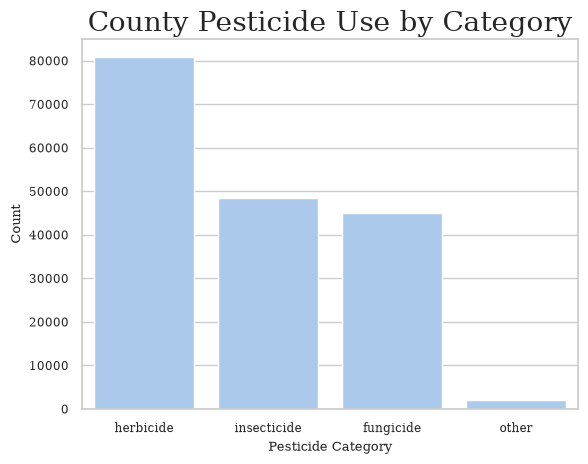

In [58]:
sns.countplot(
    data = pest_water_categorized,
    x = "Pest_Category",
).set(
    title = "County Pesticide Use by Category",
    xlabel = "Pesticide Category",
    ylabel = "Count"
);

#huzzah
# need to average the site location values per year (if there are multiple entries per year per site per pesticide)

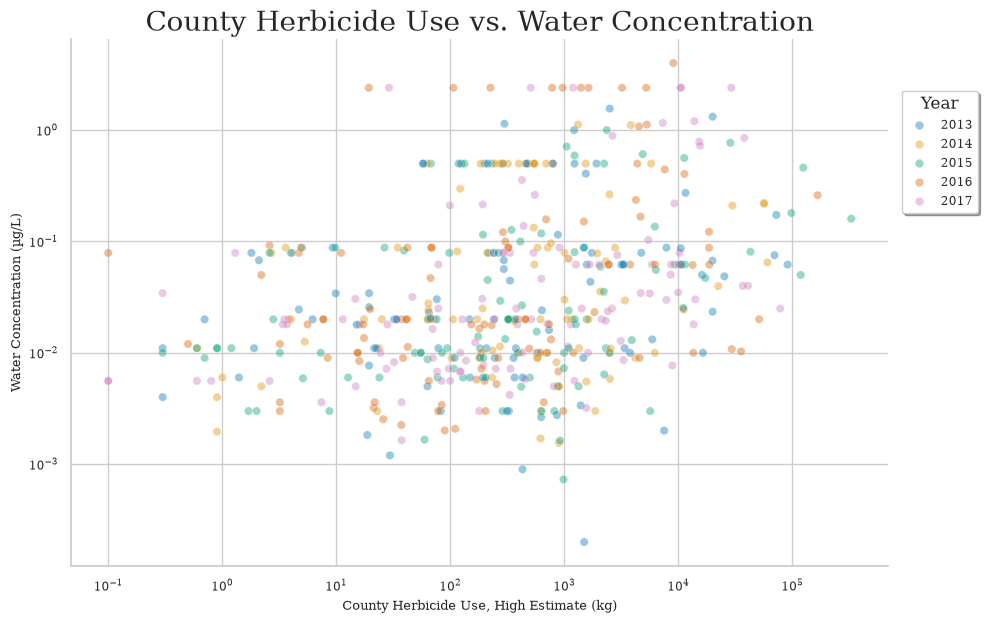

In [ ]:
# herbicide only scatterplot

herbicide_df = pest_water_categorized[pest_water_categorized["Pest_Category"] == "herbicide"].copy()

herb_plot = herbicide_df.sample(500, random_state = 1)

g = sns.relplot(
    data = herb_plot,
    x ='EPEST_HIGH_KG',
    y ='Result_Value_ug_L',
    hue ='Water_Year',
    kind ='scatter',
    alpha = 0.4,
    palette ='colorblind',
    height = 6,
    aspect = 1.5
).set(
    title ='County Herbicide Use vs. Water Concentration',
    xlabel ='County Herbicide Use, High Estimate (kg)',
    ylabel ='Water Concentration (µg/L)',
    xscale ='log',
    yscale ='log'
)

sns.move_legend(
    g,
    'upper right',
    bbox_to_anchor = (1, 0.9),
    title = 'Year',
    title_fontsize = 12,
    shadow = True,
    frameon = True
);


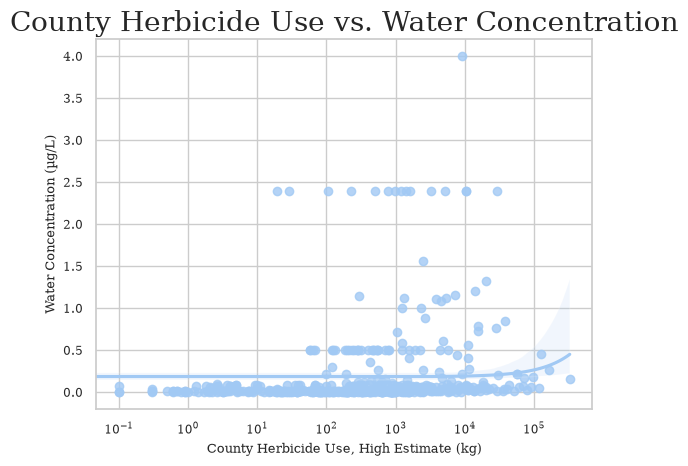

In [ ]:
# same as scatterplot, but with linear regression

g = sns.regplot(
    data = herb_plot,
    x ='EPEST_HIGH_KG',
    y ='Result_Value_ug_L',
).set(
    title ='County Herbicide Use vs. Water Concentration',
    xlabel ='County Herbicide Use, High Estimate (kg)',
    ylabel ='Water Concentration (µg/L)',
    xscale ='log'
);

#logging may be necessary

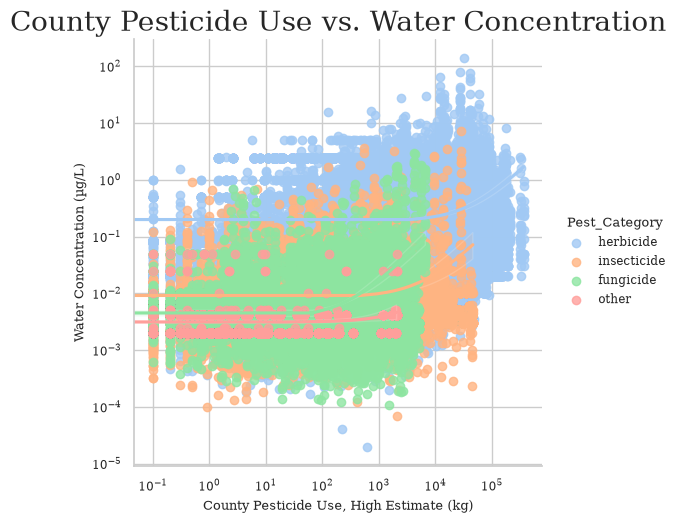

In [ ]:
pest_water_categorized_plot = pest_water_categorized.sample(500, random_state = 1)

sns.lmplot(
    data = pest_water_categorized,
    x ='EPEST_HIGH_KG',
    y ='Result_Value_ug_L',
    hue = "Pest_Category"
).set(
    title ='County Pesticide Use vs. Water Concentration',
    xlabel ='County Pesticide Use, High Estimate (kg)',
    ylabel ='Water Concentration (µg/L)',
    xscale ='log',
    yscale ='log'
)

#okay this should probably not be on one plot and instead be faceted but i am tired